# 01 Explore: Iranian Churn data

**Project:** Churn prediction and revenue at risk for a South African mobile operator.
**This notebook:** loads the data, checks what every column means, and (from Step 3) explores how churners differ from customers who stay.

Source: [Iranian Churn dataset, UCI Machine Learning Repository, id 563](https://archive.ics.uci.edu/dataset/563/iranian+churn+dataset) (CC BY 4.0).

## 1. Load the data

The raw file is kept out of Git. If it is missing, this cell downloads it once from UCI and saves an untouched copy in `data/raw/`.

In [1]:
from pathlib import Path
import pandas as pd

RAW = Path("../data/raw/customer_churn.csv")

if not RAW.exists():
    from ucimlrepo import fetch_ucirepo
    uci = fetch_ucirepo(id=563)
    pd.concat([uci.data.features, uci.data.targets], axis=1).to_csv(RAW, index=False)

raw = pd.read_csv(RAW)
print(raw.shape)
raw.head()

(3150, 14)


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


## 2. First look: types, ranges and missing values

In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)
memory usa

In [3]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Call Failure,3150.0,7.63,7.26,0.0,1.00,6.00,12.00,36.00
Complains,3150.0,0.08,0.27,0.0,0.00,0.00,0.00,1.00
Subscription Length,3150.0,32.54,8.57,3.0,30.00,35.00,38.00,47.00
Charge Amount,3150.0,0.94,1.52,0.0,0.00,0.00,1.00,10.00
Seconds of Use,3150.0,4472.46,4197.91,0.0,1391.25,2990.00,6478.25,17090.00
Frequency of use,3150.0,69.46,57.41,0.0,27.00,54.00,95.00,255.00
Frequency of SMS,3150.0,73.17,112.24,0.0,6.00,21.00,87.00,522.00
Distinct Called Numbers,3150.0,23.51,17.22,0.0,10.00,21.00,34.00,97.00
Age Group,3150.0,2.83,0.89,1.0,2.00,3.00,3.00,5.00
Tariff Plan,3150.0,1.08,0.27,1.0,1.00,1.00,1.00,2.00


No missing values, and every column is numeric. Some column names contain double spaces (`'Call  Failure'`, `'Subscription  Length'`, `'Charge  Amount'`), which makes them easy to mistype. I rename every column to `snake_case` and give each customer an ID based on their row in the raw file, so the call list at the end can be traced back to the source.

In [4]:
df = raw.copy()
df.columns = ["_".join(c.lower().split()) for c in df.columns]
df.insert(0, "customer_id", [f"C{i:04d}" for i in range(1, len(df) + 1)])
df.columns.tolist()

['customer_id',
 'call_failure',
 'complains',
 'subscription_length',
 'charge_amount',
 'seconds_of_use',
 'frequency_of_use',
 'frequency_of_sms',
 'distinct_called_numbers',
 'age_group',
 'tariff_plan',
 'status',
 'age',
 'customer_value',
 'churn']

## 3. What values do the coded columns take?

Several columns are codes, not quantities. Checking their values against the UCI documentation before using them.

In [5]:
coded = ["complains", "charge_amount", "age_group", "tariff_plan", "status", "churn"]
pd.DataFrame({c: df[c].value_counts().sort_index() for c in coded}).fillna(0).astype(int)

,complains,charge_amount,age_group,tariff_plan,status,churn
0,2909,1768,0,0,0,2655
1,241,617,123,2905,2368,495
2,0,395,1037,245,782,0
3,0,199,1425,0,0,0
4,0,76,395,0,0,0
5,0,30,170,0,0,0
6,0,11,0,0,0,0
7,0,14,0,0,0,0
8,0,19,0,0,0,0
9,0,14,0,0,0,0


Findings that go into the data dictionary:

- `complains`, `churn` are 0/1 flags. `tariff_plan` is 1 = pay as you go, 2 = contract. `status` is 1 = active, 2 = non-active.
- `charge_amount` is documented as an ordinal scale from 0 (lowest) to 9 (highest), but the data contains a value of **10** for a few customers. A small mismatch between documentation and data like this is worth recording; I treat it as the top of the scale.
- `age_group` (1 to 5) is a banded version of `age`, so the two carry the same information.

## 4. Timing: what would the business know, and when?

From the UCI documentation: *all attributes except churn are aggregated over the **first 9 months**; churn is the customer's state at the **end of month 12**; the 3 months in between are the planning gap.*

That matches the business question exactly: at month 9 the retention team gets a list, and has about three months to act before the customer leaves.

**Is `status` safe to use, or does it leak the answer?** Leakage means a feature contains information that would not be available at the moment of prediction, usually because it was recorded at the same time as (or after) the outcome. Here `status` (active or non-active) is documented as part of the 9-month aggregate, so it is known at month 9 and is a fair early warning signal: a customer who has gone quiet is likely to leave. It would be leakage if it had been recorded at month 12. Because this rests on the documentation, Step 5 also tests a model without `status` to see how much the result depends on it.

In [6]:
pd.crosstab(df["status"], df["churn"], normalize="index").round(3)

churn,0,1
status,,
1,0.947,0.053
2,0.527,0.473


## 5. Duplicates

There is no customer ID in the raw data, so I check for rows that are identical in every column.

In [7]:
dupes = raw.duplicated().sum()
print(f"Fully identical rows: {dupes} of {len(raw)} ({dupes / len(raw):.1%})")

Fully identical rows: 300 of 3150 (9.5%)


300 rows (9.5%) are exact copies of another row across all 14 columns, including continuous values like seconds of use and customer value. Two different customers matching on all of those by chance is very unlikely, so these are almost certainly duplicated records. This matters for modelling: if a row and its copy land on different sides of the train/test split, the model is tested on customers it has already seen and the scores look better than they are. I deal with this in Step 3.

---
# Step 3: Clean and explore

In [8]:
import matplotlib.pyplot as plt

# One consistent, colour-blind-safe look for every chart in this project
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
    "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW]),
})

## 6. Remove duplicated records

In [9]:
feature_cols = [c for c in df.columns if c != "customer_id"]
clean = df.drop_duplicates(subset=feature_cols, keep="first").reset_index(drop=True)
print(f"{len(df)} rows -> {len(clean)} unique customers")

3150 rows -> 2850 unique customers


## 7. The target: how many customers churn?

In [10]:
churn_rate = clean["churn"].mean()
print(f"Churn rate: {churn_rate:.1%}  ({clean['churn'].sum()} of {len(clean)} customers)")
print(f"A model that predicts 'no churn' for everyone would already be {1 - churn_rate:.1%} accurate.")

Churn rate: 15.6%  (446 of 2850 customers)
A model that predicts 'no churn' for everyone would already be 84.4% accurate.


About one customer in six churns. The classes are imbalanced, which is why accuracy is not the headline metric (see the README).

## 8. How do churners differ from customers who stay?

In [11]:
profile = clean.groupby("churn")[feature_cols[:-1]].mean().T
profile.columns = ["stayed", "churned"]
profile["churned / stayed"] = (profile["churned"] / profile["stayed"]).round(2)
profile.round(2)

,stayed,churned,churned / stayed
call_failure,7.79,7.86,1.01
complains,0.02,0.43,25.60
subscription_length,32.60,31.68,0.97
charge_amount,1.11,0.25,0.22
seconds_of_use,5069.59,1648.66,0.33
frequency_of_use,77.87,30.70,0.39
frequency_of_sms,84.35,16.85,0.20
distinct_called_numbers,25.87,13.08,0.51
age_group,2.84,2.82,0.99
tariff_plan,1.09,1.01,0.93


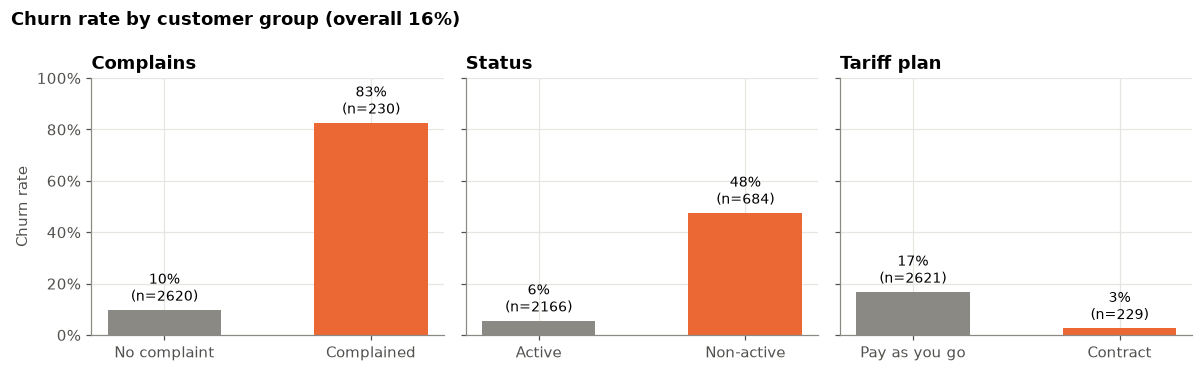

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, (col, labels) in zip(axes, [("complains", ["No complaint", "Complained"]),
                                    ("status", ["Active", "Non-active"]),
                                    ("tariff_plan", ["Pay as you go", "Contract"])]):
    rate = clean.groupby(col)["churn"].mean()
    counts = clean[col].value_counts().sort_index()
    bars = ax.bar(labels, rate.values, color=[GREY, ORANGE], width=0.55)
    for b, r, n in zip(bars, rate.values, counts.values):
        ax.annotate(f"{r:.0%}\n(n={n})", (b.get_x() + b.get_width() / 2, r), ha="center", va="bottom",
                    xytext=(0, 3), textcoords="offset points", fontsize=9)
    ax.set_title(col.replace("_", " ").capitalize())
axes[0].set_ylabel("Churn rate")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_ylim(0, 1)
fig.suptitle(f"Churn rate by customer group (overall {churn_rate:.0%})", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig("../figures/churn_rate_by_group.png")
plt.show()

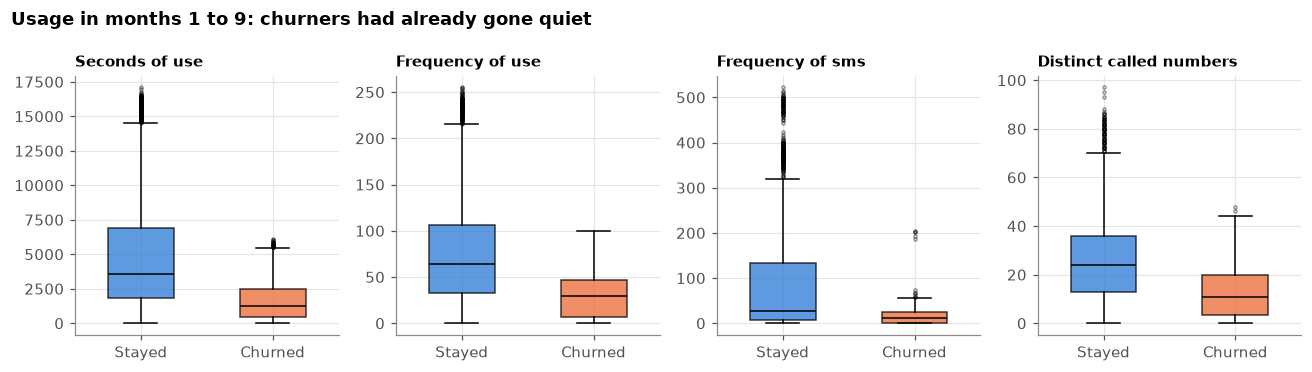

In [13]:
usage = ["seconds_of_use", "frequency_of_use", "frequency_of_sms", "distinct_called_numbers"]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, col in zip(axes, usage):
    data = [clean.loc[clean.churn == 0, col], clean.loc[clean.churn == 1, col]]
    bp = ax.boxplot(data, tick_labels=["Stayed", "Churned"], patch_artist=True, widths=0.5,
                    medianprops={"color": "black"}, flierprops={"markersize": 2, "alpha": 0.4})
    for patch, colour in zip(bp["boxes"], [BLUE, ORANGE]):
        patch.set_facecolor(colour)
        patch.set_alpha(0.75)
    ax.set_title(col.replace("_", " ").capitalize(), fontsize=10)
fig.suptitle("Usage in months 1 to 9: churners had already gone quiet", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig("../figures/usage_churners_vs_stayers.png")
plt.show()

## 9. Customer value: where does the value sit?

In [14]:
value = clean.groupby("churn")["customer_value"].agg(["count", "mean", "median", "sum"])
value.index = ["stayed", "churned"]
value["share_of_total_value"] = value["sum"] / value["sum"].sum()
print(f"Customers with a value of exactly 0: {(clean.customer_value == 0).sum()}")
value.round(3)

Customers with a value of exactly 0: 85


,count,mean,median,sum,share_of_total_value
stayed,2404,538.591,271.540,1294772.185,0.956
churned,446,132.176,102.565,58950.360,0.044


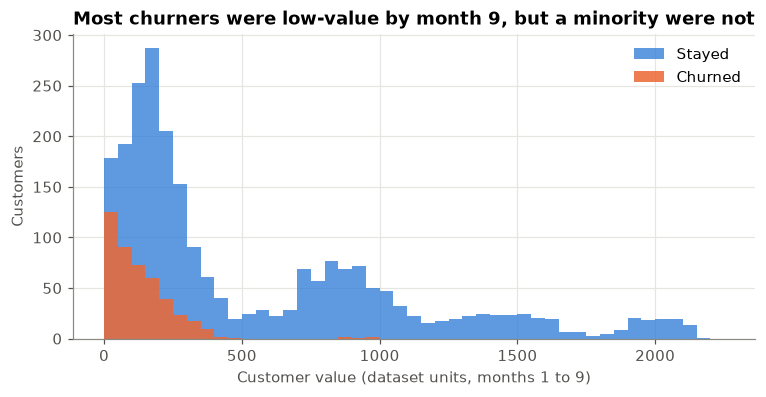

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = range(0, 2300, 50)
ax.hist(clean.loc[clean.churn == 0, "customer_value"], bins=bins, color=BLUE, alpha=0.75, label="Stayed")
ax.hist(clean.loc[clean.churn == 1, "customer_value"], bins=bins, color=ORANGE, alpha=0.85, label="Churned")
ax.set_xlabel("Customer value (dataset units, months 1 to 9)")
ax.set_ylabel("Customers")
ax.set_title("Most churners were low-value by month 9, but a minority were not")
ax.legend()
fig.savefig("../figures/customer_value_distribution.png")
plt.show()

In [16]:
churners = clean[clean.churn == 1].sort_values("customer_value", ascending=False)
top_fifth = churners.head(len(churners) // 5)
share = top_fifth.customer_value.sum() / churners.customer_value.sum()
print(f"The top 20% of churners by value hold {share:.0%} of all value lost to churn.")

The top 20% of churners by value hold 49% of all value lost to churn.


## 10. Three findings in plain English

1. **Complaints are the loudest warning sign.** Customers who complained churned at about 80%, against about 10% for those who did not. A complaint should trigger a retention contact on its own.
2. **Churners go quiet before they leave.** In months 1 to 9 they made far fewer calls, sent far fewer SMSs and called fewer distinct numbers than customers who stayed, and most of them were already flagged as non-active. The signal is there three months before they go.
3. **Most churners are low-value, but the lost value is concentrated.** Churners hold only about 4% of total customer value, and the most valuable fifth of churners account for about half of the value lost. So the call list should not just pick the most likely leavers; it should weigh how much each one is worth. That is the case for ranking by expected loss in Step 7.

Note on finding 3: customer value here is measured over months 1 to 9, while churners were already reducing their usage. Their value before they disengaged was probably higher, so this understates what the operator stands to lose.

## 11. Save the clean data for modelling

In [17]:
clean.to_csv("../data/processed/churn_clean.csv", index=False)
clean.shape

(2850, 15)